# Week 7 Take Home

This week has two parts. **Complete both.**

| Part | Lessons | Project |
|------|---------|---------|
| A. Cleaning & Visualising Data | `1-Cleaning & Visualising Data/` | Holiday weather |
| B. Transforming & Combining Data | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---

## Part A: Cleaning & Visualising Data

- Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks below
- Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks below

### Project A: Holiday weather

There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

#### Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

<http://www.wunderground.com/history>

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'.

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period **From: 1 January 2023 to: 31 December 2023** and then click on 'Get History'. The data for that year should then be displayed further down the page.

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.

Now load the CSV file into a dataframe making sure that any extra spaces are skipped.

#### Step 1: Cleaning the data

#### Step 2: Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the datetime index.

---

# Part A Step 1


In [4]:
import pandas as pd

In [5]:
data= "london_weather_2023.csv"

In [6]:
df= pd.read_csv(data, skipinitialspace= True, parse_dates=['date'])

In [7]:
df.head()

,date,temp_max_c,temp_avg_c,temp_min_c,dew_point_max_c,dew_point_avg_c,dew_point_min_c,humidity_max_pct,humidity_avg_pct,humidity_min_pct,wind_max_kmh,wind_avg_kmh,wind_min_kmh,pressure_max_hpa,pressure_avg_hpa,pressure_min_hpa,precip_mm
0,2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0.0
1,2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0.0
2,2023-01-03,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0.0
3,2023-01-04,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0.0
4,2023-01-05,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0.0


In [8]:
df.columns


Index(['date', 'temp_max_c', 'temp_avg_c', 'temp_min_c', 'dew_point_max_c',
       'dew_point_avg_c', 'dew_point_min_c', 'humidity_max_pct',
       'humidity_avg_pct', 'humidity_min_pct', 'wind_max_kmh', 'wind_avg_kmh',
       'wind_min_kmh', 'pressure_max_hpa', 'pressure_avg_hpa',
       'pressure_min_hpa', 'precip_mm'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              365 non-null    datetime64[us]
 1   temp_max_c        365 non-null    int64         
 2   temp_avg_c        365 non-null    float64       
 3   temp_min_c        365 non-null    int64         
 4   dew_point_max_c   365 non-null    int64         
 5   dew_point_avg_c   365 non-null    float64       
 6   dew_point_min_c   365 non-null    int64         
 7   humidity_max_pct  365 non-null    int64         
 8   humidity_avg_pct  365 non-null    float64       
 9   humidity_min_pct  365 non-null    int64         
 10  wind_max_kmh      365 non-null    int64         
 11  wind_avg_kmh      365 non-null    float64       
 12  wind_min_kmh      365 non-null    int64         
 13  pressure_max_hpa  365 non-null    float64       
 14  pressure_avg_hpa  365 non-null    flo

In [10]:
df.isnull().sum()

date                0
temp_max_c          0
temp_avg_c          0
temp_min_c          0
dew_point_max_c     0
dew_point_avg_c     0
dew_point_min_c     0
humidity_max_pct    0
humidity_avg_pct    0
humidity_min_pct    0
wind_max_kmh        0
wind_avg_kmh        0
wind_min_kmh        0
pressure_max_hpa    0
pressure_avg_hpa    0
pressure_min_hpa    0
precip_mm           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

### Finding the summer break

In [12]:
months_mask= ['June', 'July', 'August', 'December','January', 'February']


In [13]:
df_copy= df.copy()

In [14]:
df_copy.head()

,date,temp_max_c,temp_avg_c,temp_min_c,dew_point_max_c,dew_point_avg_c,dew_point_min_c,humidity_max_pct,humidity_avg_pct,humidity_min_pct,wind_max_kmh,wind_avg_kmh,wind_min_kmh,pressure_max_hpa,pressure_avg_hpa,pressure_min_hpa,precip_mm
0,2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0.0
1,2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0.0
2,2023-01-03,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0.0
3,2023-01-04,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0.0
4,2023-01-05,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0.0


In [15]:
df_copy['month']= df_copy['date'].dt.month_name()

In [16]:
df_copy.head()

,date,temp_max_c,temp_avg_c,temp_min_c,dew_point_max_c,dew_point_avg_c,dew_point_min_c,humidity_max_pct,humidity_avg_pct,humidity_min_pct,wind_max_kmh,wind_avg_kmh,wind_min_kmh,pressure_max_hpa,pressure_avg_hpa,pressure_min_hpa,precip_mm,month
0,2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0.0,January
1,2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0.0,January
2,2023-01-03,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0.0,January
3,2023-01-04,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0.0,January
4,2023-01-05,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0.0,January


In [17]:
summer_df= df_copy[df_copy['month'].isin(['June', 'July', 'August', 'December','January', 'February'])]

In [18]:
summer_df['month'].unique()

<StringArray>
['January', 'February', 'June', 'July', 'August', 'December']
Length: 6, dtype: str

In [19]:
summer_df= summer_df.set_index('date')

In [20]:
summer_df.head()

,temp_max_c,temp_avg_c,temp_min_c,dew_point_max_c,dew_point_avg_c,dew_point_min_c,humidity_max_pct,humidity_avg_pct,humidity_min_pct,wind_max_kmh,wind_avg_kmh,wind_min_kmh,pressure_max_hpa,pressure_avg_hpa,pressure_min_hpa,precip_mm,month
date,,,,,,,,,,,,,,,,,
2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0.0,January
2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0.0,January
2023-01-03,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0.0,January
2023-01-04,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0.0,January
2023-01-05,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0.0,January




## Part B: Transforming & Combining Data

- Provide `2-Transforming & Combining Data/1.ipynb` Tasks solutions below (execute them)
- Provide `2-Transforming & Combining Data/2.ipynb` Tasks solutions below (execute them)
- Provide `2-Transforming & Combining Data/2.ipynb` Assignment solutions below (execute them)
- Read and follow the example analysis below

### Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

#### Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

```python
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()
```

#### Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

- the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:

1. removing the first 34 rows;
2. removing rows with unavailable values.

```python
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()
```

#### Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>.

```python
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()
```

```text
        country  year  NY.GDP.MKTP.CD  GDP (£m)
34  Afghanistan  2013    2.045894e+10     13075
35      Albania  2013    1.278103e+10      8168
36      Algeria  2013    2.097035e+11    134016
38      Andorra  2013    3.249101e+09      2076
39       Angola  2013    1.383568e+11     88420
```

The unnecessary columns can be dropped.

```python
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()
```

```text
        country  GDP (£m)
34  Afghanistan     13075
35      Albania      8168
36      Algeria    134016
38      Andorra      2076
39       Angola     88420
```

The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

```python
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()
```

```text
                country  Life expectancy (years)
34          Afghanistan                       60
35              Albania                       78
36              Algeria                       75
39               Angola                       52
40  Antigua and Barbuda                       76
```

#### Combining the data

The tables are combined through an inner join on the common `country` column.

```python
gdpVsLife = merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()
```

```text
               country  GDP (£m)  Life expectancy (years)
0          Afghanistan     13075                       60
1              Albania      8168                       78
2              Algeria    134016                       75
3               Angola     88420                       52
4  Antigua and Barbuda       767                       76
```

#### Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

```python
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')
```

```text
The correlation is 0.501023238967
It is statistically significant.
```

The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

#### Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

```python
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))
```

```text
<matplotlib.axes._subplots.AxesSubplot at 0x117753898>
```

*(Output: scatterplot of life expectancy against GDP, log-scaled x-axis)*

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years.

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definition of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy.

```python
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)
```

| Index | country | GDP (£m) | Life expectancy (years) |
|------:|---------|---------:|------------------------:|
| 87 | Kiribati | 108 | 66 |
| 141 | Sao Tome and Principe | 195 | 66 |
| 111 | Micronesia, Fed. Sts. | 202 | 69 |
| 168 | Tonga | 277 | 73 |
| 37 | Comoros | 383 | 63 |
| 157 | St. Vincent and the Grenadines | 461 | 73 |
| 140 | Samoa | 509 | 73 |
| 180 | Vanuatu | 512 | 72 |
| 65 | Grenada | 538 | 73 |
| 60 | Gambia, The | 578 | 60 |

```python
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)
```

| Index | country | GDP (£m) | Life expectancy (years) |
|------:|---------|---------:|------------------------:|
| 95 | Lesotho | 1418 | 49 |
| 160 | Swaziland | 2916 | 49 |
| 32 | Central African Republic | 983 | 50 |
| 146 | Sierra Leone | 3092 | 50 |
| 33 | Chad | 8276 | 51 |
| 41 | Cote d'Ivoire | 19998 | 51 |
| 3 | Angola | 88420 | 52 |
| 124 | Nigeria | 329100 | 52 |
| 30 | Cameroon | 18896 | 55 |
| 153 | South Sudan | 8473 | 55 |

#### Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the `NY.GDP.PCAP.PP.CD` indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expenditure on health, could also lead to a better analysis.

---




## Part B: Transforming & Combining Data


In [21]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()

,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


In [22]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

In [23]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


In [24]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


In [25]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


In [26]:
gdpVsLife= gdpClean.merge(lifeClean, how='inner', on= 'country')
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


In [27]:
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.5010232389671027
It is statistically significant.


<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

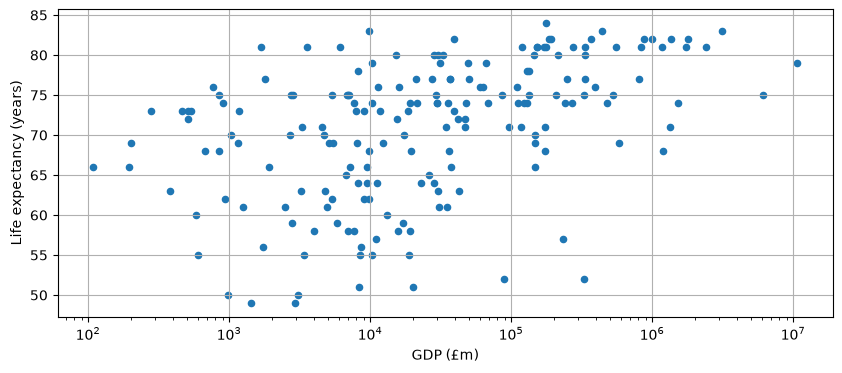

In [28]:
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))


In [29]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10).reset_index(drop= True)

,country,GDP (£m),Life expectancy (years)
0,Kiribati,108,66
1,Sao Tome and Principe,195,66
2,"Micronesia, Fed. Sts.",202,69
3,Tonga,277,73
4,Comoros,383,63
5,St. Vincent and the Grenadines,461,73
6,Samoa,509,73
7,Vanuatu,512,72
8,Grenada,538,73
9,"Gambia, The",578,60


In [30]:
gdpVsLife.sort_values(LIFE).head(10).reset_index(drop=True)


,country,GDP (£m),Life expectancy (years)
0,Lesotho,1418,49
1,Swaziland,2916,49
2,Sierra Leone,3092,50
3,Central African Republic,983,50
4,Cote d'Ivoire,19998,51
5,Chad,8276,51
6,Nigeria,329100,52
7,Angola,88420,52
8,Guinea-Bissau,605,55
9,South Sudan,8473,55


## Assessment: Now Is Your Turn

**Create your own project.** Create a completely new project and choose another two of the hundreds of World Bank indicators and see if there is any correlation between them. If there is a choice of similar indicators, choose one that leads to meaningful comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.

**GOOD LUCK!**

---

### Im checking the correlation between healthcare spending per person and Child Mortality Rate(per 1000 live births) for the year 2020

child mortality rate <https://data.worldbank.org/indicator/SP.DYN.IMRT.IN>
Healthcare expenditure per capita <https://data.worldbank.org/indicator/SH.XPD.CHEX.PC.CD>

In [31]:
import glob
import pandas as pd

def load_indicator(code, column_name, year):
    data_file = glob.glob(f"API_{code}_DS2*.csv")[0]
    meta_file = glob.glob(f"Metadata_Country_API_{code}*.csv")[0]

    df = pd.read_csv(data_file, skiprows=4)
    meta = pd.read_csv(meta_file, encoding="utf-8-sig")

    countries = meta.loc[meta["Region"].notna(), "Country Code"]
    df = df[df["Country Code"].isin(countries)]

    df = df[["Country Name", "Country Code", str(year)]]
    return df.rename(columns={str(year): column_name})

In [32]:
raw = pd.read_csv(glob.glob("API_SH.XPD.CHEX.PC.CD_DS2*.csv")[0], skiprows=4)
print(raw[[str(y) for y in range(2015, 2024)]].notna().sum())

2015    239
2016    239
2017    240
2018    241
2019    241
2020    241
2021    240
2022    239
2023    239
dtype: int64


picked the year 2020 since it has least na values

In [33]:
YEAR = 2020
HEALTH = "Health spending per person (US$)"
INFANT = "Infant mortality (per 1,000 live births)"

health = load_indicator("SH.XPD.CHEX.PC.CD", HEALTH, YEAR).dropna()
infant = load_indicator("SP.DYN.IMRT.IN", INFANT, YEAR).dropna()

In [34]:
health.head()

,Country Name,Country Code,Health spending per person (US$)
2,Afghanistan,AFG,80.089233
4,Angola,AGO,56.016418
5,Albania,ALB,396.174774
6,Andorra,AND,3282.025879
8,United Arab Emirates,ARE,2154.411133


In [35]:
infant.head()

,Country Name,Country Code,"Infant mortality (per 1,000 live births)"
2,Afghanistan,AFG,54.9
4,Angola,AGO,34.9
5,Albania,ALB,8.1
6,Andorra,AND,2.8
8,United Arab Emirates,ARE,4.7


In [36]:
print("Expenditure  nulls:")
print(health.isna().sum())
print("________________________________")
print("\n ")
print("Infant mortality nulls:")
print(infant.isna().sum())

Expenditure  nulls:
Country Name                        0
Country Code                        0
Health spending per person (US$)    0
dtype: int64
________________________________

 
Infant mortality nulls:
Country Name                                0
Country Code                                0
Infant mortality (per 1,000 live births)    0
dtype: int64


no null values, we are good to gooo!

okay, now merging the two data frames

In [37]:
health[HEALTH] = health[HEALTH].round(0)
infant[INFANT] = infant[INFANT].round(1)

combined = pd.merge(health, infant[["Country Code", INFANT]],
                    on="Country Code", how="inner")
print(len(health), len(infant), len(combined))
combined.head()

193 196 192


,Country Name,Country Code,Health spending per person (US$),"Infant mortality (per 1,000 live births)"
0,Afghanistan,AFG,80.0,54.9
1,Angola,AGO,56.0,34.9
2,Albania,ALB,396.0,8.1
3,Andorra,AND,3282.0,2.8
4,United Arab Emirates,ARE,2154.0,4.7


In [38]:
from scipy.stats import spearmanr

(corr, p_value)= spearmanr(combined[HEALTH], combined[INFANT])
print(f"correlation between Health Expenditure per capita and infant mortality per 1000 live births is: {corr}")
if (p_value < 0.05):
    print("Correlation is statistically significant")
else:
    print("Correlation is not statistically significant")

correlation between Health Expenditure per capita and infant mortality per 1000 live births is: -0.8710940730528502
Correlation is statistically significant


There is a strong negative correlation -0.87, meaning an increse in health expenditure decreses the
health mortality rate. 
This can be visualized by the scatterplot below, where countries with low health expenditure per capita, 
<100USD have a higher infant mortality rate compared to countries with an expenditure per capita of >1000USD

<Axes: xlabel='Health spending per person (US$)', ylabel='Infant mortality (per 1,000 live births)'>

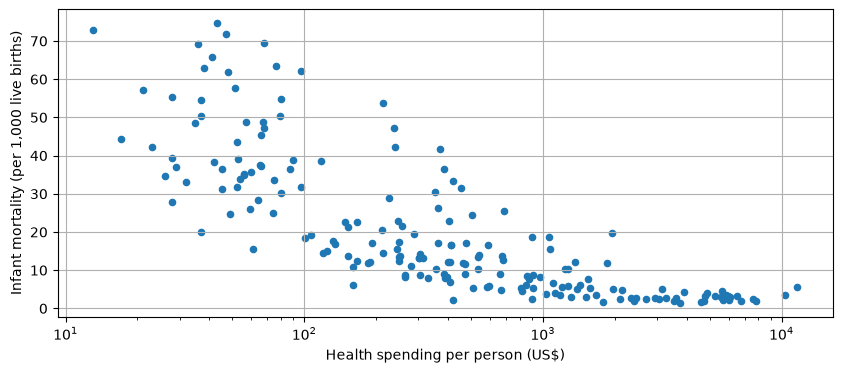

In [39]:
combined.plot(x=HEALTH, y=INFANT, kind="scatter", grid=True, logx=True, figsize=(10, 4))

In [40]:
combined.sort_values(HEALTH).head(10)


,Country Name,Country Code,Health spending per person (US$),"Infant mortality (per 1,000 live births)"
155,"Somalia, Fed. Rep.",SOM,13.0,72.9
108,Madagascar,MDG,17.0,44.3
35,"Congo, Dem. Rep.",COD,21.0,57.2
148,Sudan,SDN,23.0,42.2
11,Burundi,BDI,26.0,34.6
52,Eritrea,ERI,28.0,27.8
113,Mali,MLI,28.0,55.4
55,Ethiopia,ETH,28.0,39.4
65,"Gambia, The",GMB,29.0,37.0
177,Tanzania,TZA,32.0,33.2


In [41]:
combined.sort_values(INFANT).tail(10)

,Country Name,Country Code,Health spending per person (US$),"Infant mortality (per 1,000 live births)"
152,Sierra Leone,SLE,48.0,61.9
101,Lesotho,LSO,97.0,62.1
166,Chad,TCD,38.0,62.9
97,Liberia,LBR,76.0,63.4
64,Guinea,GIN,41.0,65.7
124,Niger,NER,36.0,69.1
125,Nigeria,NGA,68.0,69.5
157,South Sudan,SSD,47.0,71.9
155,"Somalia, Fed. Rep.",SOM,13.0,72.9
28,Central African Republic,CAF,43.0,74.7


Disclaimer! correlation isn’t causation. Wealthier countries also have better sanitation, nutrition and education. Also,total health spending per person ignores how the spending is split between public and private sector.

In [42]:
# --- Connect to the cohort database (read-only) ---
import sys, pathlib, re
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query, get_engine, get_connection

import pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

_BLOCKED = re.compile(
    r"\b(INSERT|UPDATE|DELETE|MERGE|DROP|ALTER|CREATE|TRUNCATE|EXEC|EXECUTE|GRANT|REVOKE|DENY|INTO|BACKUP|RESTORE)\b",
    re.IGNORECASE,
)

def q(sql: str) -> pd.DataFrame:
    """Run a read-only query and return a DataFrame.

    String literals and comments are stripped before the safety check, so a value
    like 'Delete me' inside quotes is fine.
    """
    scrubbed = re.sub(r"'([^']|'')*'", "''", sql)           # string literals
    scrubbed = re.sub(r"--[^\n]*", "", scrubbed)              # -- comments
    scrubbed = re.sub(r"/\*.*?\*/", "", scrubbed, flags=re.S) # /* comments */
    hit = _BLOCKED.search(scrubbed)
    if hit:
        raise PermissionError(
            f"'{hit.group(0).upper()}' is not allowed: this notebook is read-only. "
            "Shape your data inside the SELECT, or in pandas."
        )
    return run_query(sql)

q("SELECT DB_NAME() AS database_name, CURRENT_USER AS logged_in_as, SYSDATETIME() AS server_time")

,database_name,logged_in_as,server_time
0,assessmentDB,intern_readonly,2026-10-24 10:34:03.897575


## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs in SQL, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

### How it works

1. Run the practice setup cell first (and again after restarting the kernel). It connects with your read-only account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and says ✅ or ❌, and whether the shape (rows × columns) is right. Match the column order, sort order and rounding asked for (column names aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.


```python
# --- practice setup: run this cell first (don't edit it) ---

```

In [79]:
import importlib
import db.practice

importlib.reload(db.practice)

from db.practice import Practice

In [80]:
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly



### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the raw export: the last column is literally named `WindDirDegrees<br />` and every value ends in `<br />` (e.g. `'186<br />'`). Clean it in SQL: remove the `<br />`, convert to an integer, and count the days when the wind direction was greater than 350 degrees.

**Return:** one row, one column (`days_over_350`).

💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.



In [81]:
SQL_01 = """
SELECT COUNT(*) AS days_over_350
    FROM week07.london_2014
    WHERE TRY_CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS int) > 350;
"""
p.sql("s01", SQL_01)


Running s01: Cleaning a messy column


,days_over_350
0,5


✅ s01: Correct!


### SQL Task 2 · Dates: a date range

`GMT` is stored as text like `'2014-1-1'`. Convert it to a real date and return London's weather for 8–12 December 2014 (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.

💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.



In [82]:
SQL_02 = """
     SELECT 
     TRY_CONVERT(date, GMT) as day,
     [Max TemperatureC], 
     [Min TemperatureC]
FROM week07.london_2014
WHERE TRY_CONVERT(date, GMT) BETWEEN '2014-12-08' AND '2014-12-12'
ORDER BY day;
"""
p.sql("s02", SQL_02)


Running s02: Dates: a date range


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: Correct!


### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP below 10 billion USD and a known life expectancy, return the 10 with the highest life expectancy.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, rounded to 2 dp), `life_expectancy` (rounded to 1 dp), sorted by life expectancy (highest first), then country (A→Z) for ties.

In [83]:
gdp= run_query(
    """Select * from week08.wb_gdp_2013"""

)
gdp.head()

,country,year,NY.GDP.MKTP.CD
0,Arab World,2013,"2,827,557,148,210.97"
1,Caribbean small states,2013,"69,287,048,038.15"
2,Central Europe and the Baltics,2013,"1,419,383,888,513.92"
3,East Asia & Pacific (all income levels),2013,"20,846,726,977,065.70"
4,East Asia & Pacific (developing only),2013,"11,729,395,514,462.00"


In [84]:
life= run_query(
    """Select * from week08.wb_le_2013"""

)
life.head()

,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.63
1,Caribbean small states,2013,71.90
2,Central Europe and the Baltics,2013,76.13
3,East Asia & Pacific (all income levels),2013,74.60
4,East Asia & Pacific (developing only),2013,73.66


In [85]:
SQL_03 = """

SELECT TOP 10
    le.country AS country,
    ROUND(gdp.[NY.GDP.MKTP.CD] / 1000000000.0, 2) AS gdp_bn_usd,
    ROUND(le.[SP.DYN.LE00.IN], 1) AS life_expectancy
FROM week08.wb_gdp_2013 AS gdp
INNER JOIN week08.wb_le_2013 AS le
    ON gdp.country = le.country
WHERE gdp.[NY.GDP.MKTP.CD] < 10000000000
  AND le.[SP.DYN.LE00.IN] IS NOT NULL
ORDER BY
    le.[SP.DYN.LE00.IN] DESC,
    le.country ASC;
"""
p.sql("s03", SQL_03)


Running s03: Combining tables (JOIN)


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.30
1,Malta,9.64,80.70
2,Bermuda,5.57,80.60
3,Maldives,2.79,76.60
4,Antigua and Barbuda,1.20,75.80
5,Barbados,4.28,75.30
6,"Bahamas, The",8.43,75.10
7,St. Lucia,1.33,74.90
8,Montenegro,4.46,74.80
9,Seychelles,1.41,74.20


✅ s03: Correct!


### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of `week08.wb_gdp_2013` have no usable match, meaning either GDP is `NULL`, or the life-expectancy value for that country is `NULL` (or missing)?

**Return:** one row, one column (`rows_lost`).

💡 `LEFT JOIN` and test for `NULL`s on both sides.



In [86]:
SQL_04 = """
SELECT COUNT(*) AS rows_lost
FROM week08.wb_gdp_2013 AS gdp
LEFT JOIN week08.wb_le_2013 AS le
    ON gdp.country = le.country
WHERE gdp.[NY.GDP.MKTP.CD] IS NULL
   OR le.[SP.DYN.LE00.IN] IS NULL;
"""
p.sql("s04", SQL_04)


Running s04: What gets lost in a join?


,rows_lost
0,29


✅ s04: Correct!


### SQL Task 5 · Window: the driest summer week

For the Holiday weather project: using London's summer (June, July, August 2014), find the 7-day period with the least total rain. A period is identified by its start date (that day + the next 6 days, all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (rounded to 2 dp).

💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep start days whose window has a full 7 days.



In [87]:
SQL_05 = """
WITH DailyRain AS (
    SELECT
        TRY_CONVERT(date, GMT) AS day,
        TRY_CAST(
            REPLACE([Precipitationmm], '<br />', '') AS float
        ) AS rain_mm
    FROM week07.london_2014
    WHERE TRY_CONVERT(date, GMT) >= '2014-06-01'
      AND TRY_CONVERT(date, GMT) < '2014-09-01'
),
RainWindows AS (
    SELECT
        day AS start_day,
        SUM(rain_mm) OVER (
            ORDER BY day
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) AS rain_mm_7d,
        COUNT(*) OVER (
            ORDER BY day
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) AS days_in_window
    FROM DailyRain
)
SELECT TOP 1
    start_day,
    ROUND(rain_mm_7d, 2) AS rain_mm_7d
FROM RainWindows
WHERE days_in_window = 7
GROUP BY start_day, rain_mm_7d
ORDER BY rain_mm_7d ASC, start_day ASC;
"""
p.sql("s05", SQL_05)


Running s05: Window: the driest summer week


,start_day,rain_mm_7d
0,2014-06-19,0.00


✅ s05: Correct!




### Practice score

Run this when you're done.



In [88]:
p.score()


========== SQL PRACTICE SCORE ==========
Task                          Topic  Result
 s01        Cleaning a messy column Correct
 s02            Dates: a date range Correct
 s03        Combining tables (JOIN) Correct
 s04      What gets lost in a join? Correct
 s05 Window: the driest summer week Correct

Correct answers: 5
Tasks attempted: 5/5
Total score: 5/5
Percentage: 100.0%


{'correct': 5,
 'total': 5,
 'attempted': 5,
 'percentage': 100.0,
 'results':   Task                           Topic   Result
 0  s01         Cleaning a messy column  Correct
 1  s02             Dates: a date range  Correct
 2  s03         Combining tables (JOIN)  Correct
 3  s04       What gets lost in a join?  Correct
 4  s05  Window: the driest summer week  Correct}





```


```





---

## 📰 Article Link

Write a detailed article about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's URL in the empty cell below (double-click the cell to edit it).

https://medium.com/@nicolekutswa/data-cleaning-sql-joins-and-a-correlation-that-made-me-say-wait-what-3940f12997f2

the world bank section was awesome!!